# 06 — ALDH2\*2 read from the brain proteome: peptide-level confirmation

Notebook 02 predicted, from protein abundance alone, that 10 of the 36 donors carry a destabilising *ALDH2* variant.
The variant-aware re-search (notebooks 03–04) makes this testable: *ALDH2\*2* (rs671, p.Glu504Lys) replaces the reference tryptic peptide `ELGEYGLQAYTEVK` by the shorter `ELGEYGLQAYTK`.

In a TMT experiment all donors of a set are measured in the same spectrum, so the reporter ions of the variant peptide show directly which donors contribute it.

Input: `results_large/search_ALL_SETS/SET_n/psm.tsv` (FragPipe 24.0, MSFragger 4.4.1, IonQuant 1.11.20).

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
RES = ROOT / "results"
SEARCH = ROOT / "results_large" / "search_ALL_SETS"

VARIANT, REFERENCE = "ELGEYGLQAYTK", "ELGEYGLQAYTEVK"
meta = pd.read_csv(RES / "sample_map.tsv", sep="\t")
scan = pd.read_csv(RES / "two_cluster_scan.tsv", sep="\t")
pattern = scan.loc[scan["gene"] == "ALDH2", "pattern"].iloc[0]
meta["predicted_carrier"] = [c == "1" for c in pattern]          # prediction made in notebook 02, before the search
meta.groupby("group")["predicted_carrier"].sum()

group
control    5
suicide    5
Name: predicted_carrier, dtype: int64

In [2]:
rows, psm_counts = [], []
for s in range(1, 5):
    psm = pd.read_csv(SEARCH / f"SET_{s}" / "psm.tsv", sep="\t", low_memory=False)
    cols = [c for c in psm.columns if c.startswith("Intensity ")]
    for pep, kind in [(VARIANT, "variant"), (REFERENCE, "reference")]:
        hit = psm[psm["Peptide"] == pep]
        psm_counts.append((s, kind, len(hit), hit["Qvalue"].max() if len(hit) else np.nan))
        for c in cols:
            rows.append((s, c.replace("Intensity ", ""), kind, hit[c].sum()))
pd.DataFrame(psm_counts, columns=["tmt_set", "peptide", "PSMs", "max q-value"]).pivot(index="tmt_set", columns="peptide", values="PSMs")

peptide,reference,variant
tmt_set,,
1,35,1
2,30,2
3,32,4
4,27,4


The variant peptide is identified in every TMT set (PSM q-value < 0.01 in all cases).

For each donor, the share of the set's variant-peptide signal is divided by the share of the set's reference-peptide signal.
Co-isolated ions add a background to every channel in MS2-based TMT quantification, so non-carriers are expected to show a low but non-zero value.

In [3]:
t = pd.DataFrame(rows, columns=["tmt_set", "sample", "peptide", "intensity"]).pivot_table(index=["tmt_set", "sample"], columns="peptide", values="intensity").reset_index()
for k in ["variant", "reference"]:
    t[k + "_share"] = t.groupby("tmt_set")[k].transform(lambda v: v / v.sum())
t["variant_to_reference"] = t["variant_share"] / t["reference_share"]
d = meta.merge(t, on=["tmt_set", "sample"])
d["log2_ratio"] = np.log2(d["variant_to_reference"])
gap = d.sort_values("log2_ratio")["log2_ratio"].diff().max()
cut = d.sort_values("log2_ratio")["log2_ratio"].diff().idxmax()
d["carrier_by_peptide"] = d["log2_ratio"] >= d.loc[cut, "log2_ratio"]
d.to_csv(RES / "ALDH2_variant_peptide_per_donor.tsv", sep="\t", index=False)
print("largest gap in log2(variant/reference): %.2f" % gap)
pd.crosstab(d["predicted_carrier"].rename("predicted from protein level (nb 02)"), d["carrier_by_peptide"].rename("carrier by variant peptide"))

largest gap in log2(variant/reference): 2.35


carrier by variant peptide,False,True
predicted from protein level (nb 02),,
False,26,0
True,0,10


In [4]:
c = d[d["carrier_by_peptide"]]; n = d[~d["carrier_by_peptide"]]
tab = [[int((c["group"] == "suicide").sum()), int((n["group"] == "suicide").sum())], [int((c["group"] == "control").sum()), int((n["group"] == "control").sum())]]
print("carriers: %d/36 (%.0f%%); suicide %d/23, control %d/13; Fisher p = %.2f" % (len(c), 100 * len(c) / 36, tab[0][0], tab[1][0], stats.fisher_exact(tab)[1]))
print("variant/reference ratio: carriers %.1f-%.1f, non-carriers %.2f-%.2f" % (c["variant_to_reference"].min(), c["variant_to_reference"].max(), n["variant_to_reference"].min(), n["variant_to_reference"].max()))
print("reference peptide in carriers relative to non-carriers: %.2f-fold" % (c["reference_share"].mean() / n["reference_share"].mean()))

carriers: 10/36 (28%); suicide 5/23, control 5/13; Fisher p = 0.44
variant/reference ratio: carriers 3.9-17.1, non-carriers 0.18-0.76
reference peptide in carriers relative to non-carriers: 0.33-fold


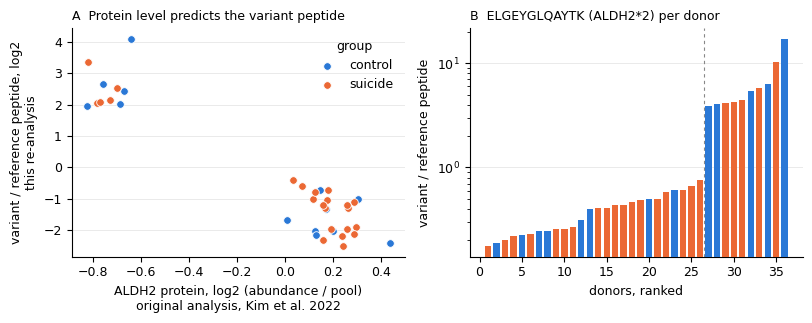

In [5]:
COL = {"control": "#2a78d6", "suicide": "#eb6834"}
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 9, "axes.spines.top": False, "axes.spines.right": False})
L = pd.read_csv(RES / "two_cluster_scan.tsv", sep="\t")
auth = pd.read_excel(ROOT / "data_external" / "Kim2022_MOESM2_ESM.xlsx", sheet_name="Table S2", header=None, skiprows=3)
prot = np.log2(pd.to_numeric(auth[auth[3] == "ALDH2"].iloc[0, 16:52], errors="coerce").to_numpy(dtype=float))
d["protein_log2"] = prot                                          # same sample order as sample_map

fig, ax = plt.subplots(1, 2, figsize=(8.2, 3.3))
for g, sub in d.groupby("group"):
    ax[0].scatter(sub["protein_log2"], sub["log2_ratio"], s=30, color=COL[g], edgecolor="white", linewidth=0.6, label=g, zorder=3)
ax[0].set_xlabel("ALDH2 protein, log2 (abundance / pool)\noriginal analysis, Kim et al. 2022")
ax[0].set_ylabel("variant / reference peptide, log2\nthis re-analysis")
ax[0].set_title("A  Protein level predicts the variant peptide", fontsize=9, loc="left")
ax[0].legend(frameon=False, title="group", loc="upper right")
order = d.sort_values("log2_ratio").reset_index(drop=True)
ax[1].bar(range(1, 37), order["variant_to_reference"], color=[COL[g] for g in order["group"]], width=0.75, zorder=3)
ax[1].set_yscale("log"); ax[1].set_xlabel("donors, ranked"); ax[1].set_ylabel("variant / reference peptide")
ax[1].axvline(36 - order["carrier_by_peptide"].sum() + 0.5, color="#888888", lw=0.8, ls=(0, (3, 3)))
ax[1].set_title("B  ELGEYGLQAYTK (ALDH2*2) per donor", fontsize=9, loc="left")
for a in ax:
    a.grid(axis="y", color="#e6e6e6", lw=0.6); a.set_axisbelow(True)
fig.tight_layout(); fig.savefig(RES / "fig_ALDH2_variant_peptide.png", dpi=300); plt.show()

## Result

- The 10 donors predicted to be carriers from protein abundance (notebook 02) are exactly the 10 donors with a high variant-to-reference peptide signal; the other 26 show only the background expected from co-isolation. The two groups do not overlap.
- Carrier frequency (10/36, 28%) is in the range reported for *ALDH2\*2* in East Asian populations, and carriers are not enriched in either group.
- The reference peptide is reduced in carriers, as expected when one allele no longer produces it and the variant subunit destabilises the enzyme.

## What this shows

Donor genotype at a pharmacogenetically relevant locus can be read from a public brain proteome with an open, documented workflow.
Zygosity cannot be assigned with confidence from MS2-level TMT data because of ratio compression.